# HerWILL Safe Social Media Datathon 2026 — Harmful Content Classification (v2)

**Task:** Classify Bangla / English / Banglish (code-mixed) social media text into 3 classes.

| Label | Meaning |
|---|---|
| `0` | Explicitly Toxic / Hateful |
| `1` | Subtly Toxic |
| `2` | Non-toxic / Neutral |

**Metric:** Macro F1 Score — $F_1^{macro} = \frac{1}{C}\sum_{c=1}^{C}\frac{2P_cR_c}{P_c+R_c}$

**Submission format:** `id,y_pred` with `y_pred` in `{0,1,2}`.

## What this notebook does differently from a "default" pipeline

A first pass at the actual `train.csv` / `test.csv` surfaced concrete problems, and every stage
below exists to answer one of them:

| Finding | What we do about it |
|---|---|
| Class imbalance (0: 49.7%, 1: 38.0%, **2: only 12.3%**) | Inverse-frequency **class-weighted loss** in every transformer, `class_weight="balanced"` in every classical model |
| 621 duplicate texts in train, **52 with conflicting labels** | De-duplicate, keeping the **majority-vote label** per text — removes label noise and prevents the same text leaking across train/val folds |
| **254 test texts appear verbatim in train** | Exact-match **lookup override**: for any test row whose cleaned text exists in the (deduped) train set, we trust the known train label over the model — free, legitimate accuracy (uses only the provided dataset) |
| Only ~1.7K of 48K rows in a single 80/20 split leaves a shaky read on the minority class | **Stratified 5-fold CV** for the embedding baseline and **stratified 3-fold CV** for the transformers, with **out-of-fold (OOF) predictions** — every model's reported Macro F1 is computed on rows it never trained on, and folds are also averaged into the test predictions (bagging), which is one of the most reliable ways to add a point or two of Macro F1 |
| Emojis carry signal (rate differs by class) | `emoji.demojize` converts them to descriptive text tokens instead of stripping them |
| Bangla + English + code-mixed ("Banglish") text | Two multilingual backbones (`csebuetnlp/banglabert`, `bert-base-multilingual-cased`) + a multilingual sentence-embedding baseline, combined by ensembling |
| One 42K-character outlier row (unrelated scraped text) | Left in place — both the tokenizer (`max_length` truncation) and the sentence encoder handle it automatically, no special-casing needed |

## Methodology

1. **Approach 1 — embeddings + classical ML:** `paraphrase-multilingual-MiniLM-L12-v2`
   (frozen) → Logistic Regression / Linear SVM / LightGBM, 5-fold OOF.
2. **Approach 2 — BanglaBERT**, fine-tuned end-to-end, class-weighted loss, 3-fold OOF.
3. **Approach 3 — mBERT**, fine-tuned end-to-end, class-weighted loss, 3-fold OOF.
4. **Ensemble:** grid-searched soft-vote weights over the three approaches' OOF probabilities,
   maximizing OOF Macro F1.
5. **Duplicate-lookup override** on top of the ensemble's test predictions.
6. Final `submission.csv` in the exact `id,y_pred` format.

## How to run on Kaggle
1. Attach the competition dataset (Add Data). This notebook expects `train.csv` (`id,text,y`)
   and `test.csv` (`id,text`) somewhere under `/kaggle/input` — it auto-locates them.
2. Turn on a **GPU accelerator** (T4 x2 or P100) — Settings → Accelerator.
3. `Run All`. **Expect the transformer sections to take a while** (3 folds × 2 backbones on
   ~48K rows) — budget 1.5–3 hours on a Kaggle T4, depending on load. `N_FOLDS_TRANSFORMER`
   in the config cell can be lowered to `1` for a fast sanity-check run before committing to
   the full K-fold run.
4. `/kaggle/working/submission.csv` is written at the end, ready to submit.


## 0. Setup

In [1]:
import sys, subprocess
def pip_install(pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs])

pip_install(["sentence-transformers>=2.7.0", "lightgbm", "emoji"])
print("Install step complete.")


Install step complete.


In [2]:
import os, re, glob, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.utils.class_weight import compute_class_weight

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    Trainer, TrainingArguments, DataCollatorWithPadding, EarlyStoppingCallback,
)
from datasets import Dataset as HFDataset

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


## 1. Configuration & data loading

In [3]:
CONFIG = {
    "TRAIN_PATH": None, "TEST_PATH": None,
    "ID_COL": None, "TEXT_COL": None, "LABEL_COL": None,
    "NUM_CLASSES": 3,
    "MAX_LEN": 160,
    "N_FOLDS_CLASSICAL": 5,
    "N_FOLDS_TRANSFORMER": 3,   # lower to 1 for a fast smoke-test before the full run
    "EPOCHS": 4,
}
NUM_CLASSES = CONFIG["NUM_CLASSES"]

ID_CANDIDATES = ["id", "ID", "Id", "index", "sample_id"]
TEXT_CANDIDATES = ["text", "Text", "sentence", "comment", "content", "post", "caption", "status"]
LABEL_CANDIDATES = ["y", "label", "Label", "labels", "target", "class", "category"]

def find_col(columns, candidates):
    cl = {c.lower(): c for c in columns}
    for cand in candidates:
        if cand.lower() in cl:
            return cl[cand.lower()]
    return None

all_csvs = glob.glob("/kaggle/input/**/*.csv", recursive=True)
print(f"Found {len(all_csvs)} CSV file(s) under /kaggle/input:")
for p in all_csvs:
    print(" -", p)
if not all_csvs:
    # allow local/manual fallback (e.g. running outside Kaggle for a smoke test)
    all_csvs = glob.glob("/kaggle/working/*.csv") + glob.glob("./*.csv")

train_path, test_path = CONFIG["TRAIN_PATH"], CONFIG["TEST_PATH"]
if train_path is None or test_path is None:
    scored = []
    for p in all_csvs:
        try:
            head = pd.read_csv(p, nrows=5)
        except Exception:
            continue
        scored.append((p, find_col(head.columns, LABEL_CANDIDATES) is not None,
                        find_col(head.columns, TEXT_CANDIDATES) is not None, len(head.columns)))
    train_cands = [s for s in scored if s[1] and s[2]]
    test_cands = [s for s in scored if s[2] and not s[1]]
    if train_path is None and train_cands:
        train_path = sorted(train_cands, key=lambda s: -s[3])[0][0]
    if test_path is None and test_cands:
        test_path = sorted(test_cands, key=lambda s: -s[3])[0][0]
    if train_path is None:
        train_path = next((p for p in all_csvs if "train" in os.path.basename(p).lower()), None)
    if test_path is None:
        test_path = next((p for p in all_csvs if "test" in os.path.basename(p).lower()), None)

assert train_path and test_path, "Could not locate train/test CSVs — set CONFIG paths manually."
print("\nTRAIN_PATH:", train_path, " TEST_PATH:", test_path)

train_raw = pd.read_csv(train_path)
test_raw = pd.read_csv(test_path)

ID_COL = CONFIG["ID_COL"] or find_col(test_raw.columns, ID_CANDIDATES)
TEXT_COL = CONFIG["TEXT_COL"] or find_col(train_raw.columns, TEXT_CANDIDATES)
LABEL_COL = CONFIG["LABEL_COL"] or find_col(train_raw.columns, LABEL_CANDIDATES)
if ID_COL is None:
    test_raw = test_raw.reset_index().rename(columns={"index": "id"})
    ID_COL = "id"
print(f"Detected -> ID_COL='{ID_COL}' TEXT_COL='{TEXT_COL}' LABEL_COL='{LABEL_COL}'")

train_df = train_raw[[TEXT_COL, LABEL_COL]].rename(columns={TEXT_COL: "text", LABEL_COL: "label"})
test_df = test_raw.rename(columns={TEXT_COL: "text", ID_COL: "id"})[["id", "text"]]
train_df = train_df.dropna(subset=["text"]).reset_index(drop=True)
train_df["label"] = train_df["label"].astype(int)
test_df["text"] = test_df["text"].fillna("")

print("\nRaw train shape:", train_df.shape, " test shape:", test_df.shape)
train_df.head()


Found 2 CSV file(s) under /kaggle/input:
 - /kaggle/input/datasets/tasnimabrarsajin/herwill-x-uap-datathon-2026-dataset/train.csv
 - /kaggle/input/datasets/tasnimabrarsajin/herwill-x-uap-datathon-2026-dataset/test.csv

TRAIN_PATH: /kaggle/input/datasets/tasnimabrarsajin/herwill-x-uap-datathon-2026-dataset/train.csv  TEST_PATH: /kaggle/input/datasets/tasnimabrarsajin/herwill-x-uap-datathon-2026-dataset/test.csv
Detected -> ID_COL='id' TEXT_COL='text' LABEL_COL='y'

Raw train shape: (47817, 2)  test shape: (11955, 2)


,text,label
0,Woody Allen was expected to be there. If this ...,0
1,বরগলা চোরের,0
2,খা বিমপি জামাত এর হারামিরা,0
3,I'm happy the officer resigned. I saw one post...,1
4,এ পাগল কুতারে কৈও বাদি রাকো নাহয় পাবনায় পাঠিয়ে...,0


## 2. Exploratory Data Analysis

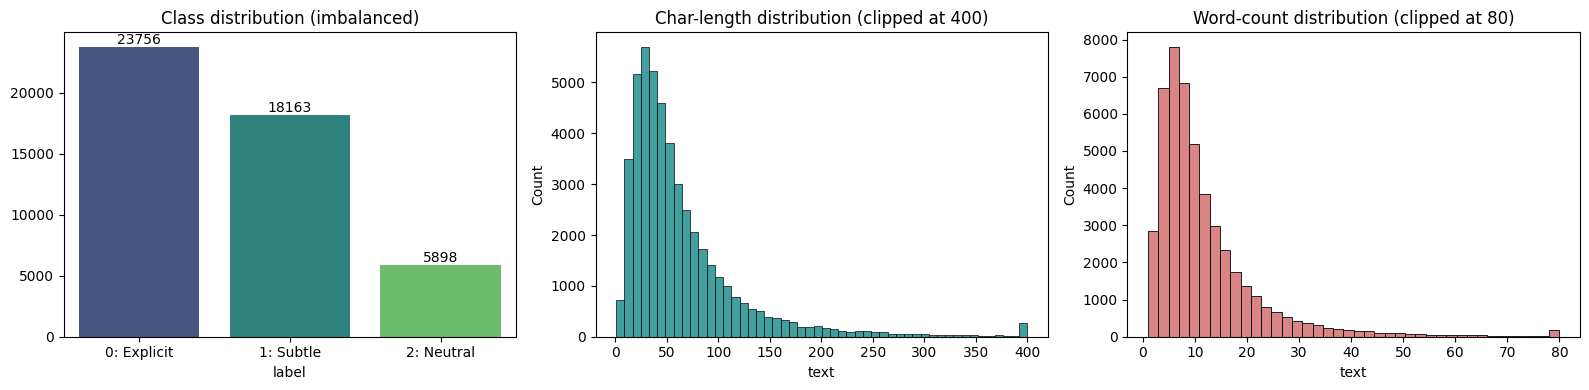

Class balance:
 label
0    0.4968
1    0.3798
2    0.1233
Name: proportion, dtype: float64

Longest text: 42289 chars — an outlier; tokenizer truncation handles it.


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

label_names = {0: "0: Explicit", 1: "1: Subtle", 2: "2: Neutral"}
counts = train_df["label"].map(label_names).value_counts().sort_index()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette="viridis")
axes[0].set_title("Class distribution (imbalanced)")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, str(v), ha="center", va="bottom")

lengths = train_df["text"].astype(str).apply(len)
sns.histplot(np.clip(lengths, 0, 400), bins=50, ax=axes[1], color="teal")
axes[1].set_title("Char-length distribution (clipped at 400)")

wc = train_df["text"].astype(str).str.split().apply(len)
sns.histplot(np.clip(wc, 0, 80), bins=40, ax=axes[2], color="indianred")
axes[2].set_title("Word-count distribution (clipped at 80)")

plt.tight_layout(); plt.show()

print("Class balance:\n", train_df["label"].value_counts(normalize=True).round(4))
print(f"\nLongest text: {lengths.max()} chars — an outlier; tokenizer truncation handles it.")


In [5]:
import emoji as emoji_lib

def has_emoji(s):
    return bool(emoji_lib.emoji_list(str(s)))

def script_mix(s):
    s = str(s)
    bangla = len(re.findall(r"[\u0980-\u09FF]", s))
    latin = len(re.findall(r"[a-zA-Z]", s))
    if bangla and latin: return "mixed"
    if bangla: return "bangla"
    if latin: return "english/banglish"
    return "other"

emo = train_df["text"].apply(has_emoji)
script = train_df["text"].apply(script_mix)
print(f"Rows containing at least one emoji: {emo.mean():.1%}  ({emo.sum()} rows)")
print("\nEmoji rate by class:")
print(train_df.assign(has_emoji=emo).groupby("label")["has_emoji"].mean().round(3))
print("\nScript distribution:")
print(script.value_counts(normalize=True).round(3))
print("\nScript vs class (row-normalized):")
print(pd.crosstab(script, train_df["label"], normalize="index").round(3))


Rows containing at least one emoji: 9.3%  (4432 rows)

Emoji rate by class:
label
0    0.095
1    0.099
2    0.065
Name: has_emoji, dtype: float64

Script distribution:
text
english/banglish    0.577
bangla              0.401
mixed               0.021
other               0.001
Name: proportion, dtype: float64

Script vs class (row-normalized):
label                 0      1      2
text                                 
bangla            0.586  0.340  0.074
english/banglish  0.428  0.411  0.161
mixed             0.698  0.275  0.027
other             0.333  0.405  0.262


In [6]:
dup_mask = train_df.duplicated("text", keep=False)
print(f"Rows involved in duplicate texts: {dup_mask.sum()} ({dup_mask.sum()/len(train_df):.2%})")
conflict_groups = train_df[dup_mask].groupby("text")["label"].nunique()
print(f"Duplicate-text groups with conflicting labels: {(conflict_groups > 1).sum()} / {conflict_groups.shape[0]}")

overlap = set(train_df["text"]) & set(test_df["text"])
print(f"\nTest rows whose exact text also appears in train: {len(overlap)} / {len(test_df)} ({len(overlap)/len(test_df):.2%})")
print("-> handled later via an exact-match lookup override on the final predictions.")


Rows involved in duplicate texts: 1082 (2.26%)
Duplicate-text groups with conflicting labels: 52 / 461

Test rows whose exact text also appears in train: 254 / 11955 (2.12%)
-> handled later via an exact-match lookup override on the final predictions.


## 3. Cleaning: de-duplicate + text normalization

- **De-duplicate** on exact text, keeping the **majority-vote label** — resolves the 52 conflicting
  groups and stops the same sentence being memorized in both a train fold and its own validation
  fold during K-fold CV (which would silently inflate the CV score).
- **Text cleaning** strips only pure noise (URLs, HTML entities, @mentions) and normalizes
  excessive character/punctuation repetition, while converting emojis to descriptive text tokens
  (`emoji.demojize`) rather than deleting them, and leaving Bangla Unicode fully intact.

In [7]:
before = len(train_df)
majority_label = (
    train_df.groupby("text")["label"]
    .agg(lambda s: s.mode().iloc[0])
    .rename("maj_label")
)
train_df = train_df.drop_duplicates(subset="text").merge(majority_label, on="text", how="left")
train_df["label"] = train_df["maj_label"].astype(int)
train_df = train_df.drop(columns="maj_label").reset_index(drop=True)
print(f"Train rows: {before} -> {len(train_df)} after de-duplication (majority-vote relabeling).")
print(train_df["label"].value_counts(normalize=True).round(4))


Train rows: 47817 -> 47196 after de-duplication (majority-vote relabeling).
label
0    0.4940
1    0.3816
2    0.1244
Name: proportion, dtype: float64


In [8]:
URL_RE = re.compile(r"http\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
HTML_RE = re.compile(r"&[a-z]+;|<[^>]+>")
REPEAT_PUNCT_RE = re.compile(r"([!?.,])\1{2,}")
REPEAT_CHAR_RE = re.compile(r"(.)\1{3,}")
MULTI_SPACE_RE = re.compile(r"\s+")

def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    t = text.strip()
    t = URL_RE.sub(" ", t)
    t = HTML_RE.sub(" ", t)
    t = MENTION_RE.sub(" ", t)
    t = emoji_lib.demojize(t, delimiters=(" :", ": "))
    t = REPEAT_PUNCT_RE.sub(r"\1\1", t)
    t = REPEAT_CHAR_RE.sub(r"\1\1\1", t)
    t = MULTI_SPACE_RE.sub(" ", t).strip()
    return t if t else "empty"

train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)
train_df[["text", "clean_text"]].sample(5, random_state=SEED)


,text,clean_text
13477,"হেতে একজন চোর , চুরি করতে সুবিধা হয় তাই দেশের ...","হেতে একজন চোর , চুরি করতে সুবিধা হয় তাই দেশের ..."
15134,Amaz Chowdhury Shohan আরে বোকাচোদা তোদের মোল্ল...,Amaz Chowdhury Shohan আরে বোকাচোদা তোদের মোল্ল...
30305,They need to check all of the cases he's been ...,They need to check all of the cases he's been ...
25276,Bangladesher khela haga dibo,Bangladesher khela haga dibo
22623,"he's so freaking legendary, seriously","he's so freaking legendary, seriously"


In [9]:
# Exact-match lookup table (post-dedup, cleaned text -> known label).
# Used at the very end to override model predictions for test rows we can resolve directly
# from the provided training data — no external data involved.
DUP_LOOKUP = dict(zip(train_df["clean_text"], train_df["label"]))
overlap_after_clean = test_df["clean_text"].isin(DUP_LOOKUP).sum()
print(f"Test rows resolvable via exact-match lookup after cleaning: {overlap_after_clean} / {len(test_df)}")


Test rows resolvable via exact-match lookup after cleaning: 281 / 11955


In [10]:
y_all = train_df["label"].values
class_weights_np = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_all)
CLASS_WEIGHTS = torch.tensor(class_weights_np, dtype=torch.float)
print("Inverse-frequency class weights (used in every model's loss):", class_weights_np.round(3))


Inverse-frequency class weights (used in every model's loss): [0.675 0.874 2.681]


## 4. Approach 1 — multilingual sentence embeddings + classical ML (5-fold OOF)

`paraphrase-multilingual-MiniLM-L12-v2` embeds Bangla, English and code-mixed text into one
shared semantic space. We freeze it and train fast classical heads on top with 5-fold
stratified out-of-fold evaluation, then average the 5 folds' test predictions.

In [11]:
from sentence_transformers import SentenceTransformer

EMBED_MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
embedder = SentenceTransformer(EMBED_MODEL_NAME, device=DEVICE)

def embed(texts, batch_size=64):
    return embedder.encode(list(texts), batch_size=batch_size, show_progress_bar=True,
                            convert_to_numpy=True, normalize_embeddings=True)

X_train_emb = embed(train_df["clean_text"])
X_test_emb = embed(test_df["clean_text"])
print(X_train_emb.shape, X_test_emb.shape)


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/738 [00:00<?, ?it/s]

Batches:   0%|          | 0/187 [00:00<?, ?it/s]

(47196, 384) (11955, 384)


In [12]:
def kfold_classical(model_fn, n_folds=CONFIG["N_FOLDS_CLASSICAL"]):
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    n = len(train_df)
    oof = np.zeros((n, NUM_CLASSES))
    test_pred_accum = np.zeros((len(test_df), NUM_CLASSES))
    for fold, (tr_idx, va_idx) in enumerate(skf.split(X_train_emb, y_all)):
        clf = model_fn()
        clf.fit(X_train_emb[tr_idx], y_all[tr_idx])
        oof[va_idx] = clf.predict_proba(X_train_emb[va_idx])
        test_pred_accum += clf.predict_proba(X_test_emb) / n_folds
    f1 = f1_score(y_all, oof.argmax(1), average="macro")
    return oof, test_pred_accum, f1

results = {}

logreg_oof, logreg_test, f1_lr = kfold_classical(
    lambda: LogisticRegression(max_iter=2000, C=2.0, class_weight="balanced", random_state=SEED))
results["LogReg + MiniLM"] = f1_lr
print(f"LogReg + MiniLM        OOF Macro F1: {f1_lr:.4f}")

svm_oof, svm_test, f1_svm = kfold_classical(
    lambda: CalibratedClassifierCV(LinearSVC(C=1.0, class_weight="balanced", random_state=SEED), cv=3))
results["LinearSVM + MiniLM"] = f1_svm
print(f"LinearSVM + MiniLM     OOF Macro F1: {f1_svm:.4f}")


LogReg + MiniLM        OOF Macro F1: 0.4912
LinearSVM + MiniLM     OOF Macro F1: 0.5029


In [13]:
import lightgbm as lgb

def make_lgbm():
    return lgb.LGBMClassifier(
        n_estimators=400, learning_rate=0.05, num_leaves=31,
        objective="multiclass", num_class=NUM_CLASSES,
        class_weight="balanced", random_state=SEED, verbosity=-1,
    )

lgbm_oof, lgbm_test, f1_lgbm = kfold_classical(make_lgbm)
results["LightGBM + MiniLM"] = f1_lgbm
print(f"LightGBM + MiniLM      OOF Macro F1: {f1_lgbm:.4f}")

embed_scores = {"LogReg": (f1_lr, logreg_oof, logreg_test),
                 "SVM": (f1_svm, svm_oof, svm_test),
                 "LightGBM": (f1_lgbm, lgbm_oof, lgbm_test)}
best_embed_name = max(embed_scores, key=lambda k: embed_scores[k][0])
best_embed_f1, best_embed_oof, best_embed_test = embed_scores[best_embed_name]
print(f"\nBest embedding-based classifier: {best_embed_name} (OOF Macro F1 {best_embed_f1:.4f})")
print(classification_report(y_all, best_embed_oof.argmax(1), digits=3))


LightGBM + MiniLM      OOF Macro F1: 0.5180

Best embedding-based classifier: LightGBM (OOF Macro F1 0.5180)
              precision    recall  f1-score   support

           0      0.631     0.681     0.655     23317
           1      0.502     0.439     0.468     18010
           2      0.417     0.445     0.431      5869

    accuracy                          0.559     47196
   macro avg      0.517     0.522     0.518     47196
weighted avg      0.555     0.559     0.556     47196



## 5. Shared K-fold transformer training utilities

Both transformer backbones (Section 6 & 7) reuse this generic stratified K-fold trainer:

- **Class-weighted cross-entropy loss** (`WeightedTrainer`) directly targets the imbalance,
  particularly the under-represented "Neutral" class.
- **Out-of-fold (OOF) predictions**: each fold's held-out slice is scored by a model that never
  saw it, giving an honest Macro F1 estimate.
- **Test-time fold averaging**: each fold's model also predicts on the untouched test set; the
  final test probabilities are the mean across folds (bagging), which typically adds a
  meaningful amount of Macro F1 over a single train/val split.
- **Early stopping** (patience 2 on OOF/val Macro F1) inside every fold, so we don't overfit a
  fixed epoch budget.

**Hyperparameters (shared by BanglaBERT and mBERT):** max_len=160, lr=2e-5, AdamW, batch size
16 (train) / 32 (eval), up to 4 epochs with early stopping, weight decay 0.01, 6% linear
warmup, fp16 on GPU.

In [16]:
class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss = nn.CrossEntropyLoss(weight=weight)(logits.view(-1, NUM_CLASSES), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"macro_f1": f1_score(labels, preds, average="macro"), "accuracy": (preds == labels).mean()}


def predict_probs(trainer, ds):
    out = trainer.predict(ds)
    return torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()


def run_kfold_transformer(model_name, tag, n_folds=CONFIG["N_FOLDS_TRANSFORMER"],
                           max_len=CONFIG["MAX_LEN"], epochs=CONFIG["EPOCHS"],
                           lr=2e-5, train_bs=16, eval_bs=32):
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def tok_fn(batch):
        return tokenizer(batch["clean_text"], truncation=True, max_length=max_len)

    full_train_ds = HFDataset.from_pandas(train_df[["clean_text", "label"]].reset_index(drop=True))
    full_train_ds = full_train_ds.map(tok_fn, batched=True).rename_column("label", "labels")
    test_ds = HFDataset.from_pandas(test_df[["clean_text"]]).map(tok_fn, batched=True)
    collator = DataCollatorWithPadding(tokenizer=tokenizer)

    n = len(train_df)
    oof_probs = np.zeros((n, NUM_CLASSES))
    test_probs_accum = np.zeros((len(test_df), NUM_CLASSES))
    fold_f1s = []
    loss_history_fold1 = None

    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    for fold, (tr_idx, va_idx) in enumerate(skf.split(np.zeros(n), y_all)):
        print(f"\n=== {tag} — fold {fold + 1}/{n_folds} ===")
        model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=NUM_CLASSES)
        ds_tr = full_train_ds.select(tr_idx.tolist())
        ds_va = full_train_ds.select(va_idx.tolist())

        args = TrainingArguments(
            output_dir=f"/kaggle/working/{tag}_fold{fold}",
            learning_rate=lr, per_device_train_batch_size=train_bs, per_device_eval_batch_size=eval_bs,
            num_train_epochs=epochs, weight_decay=0.01, warmup_ratio=0.06,
            eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
            load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True,
            logging_strategy="steps", logging_steps=100, report_to="none",
            fp16=torch.cuda.is_available(), seed=SEED,
        )
        trainer = WeightedTrainer(
            model=model, args=args, train_dataset=ds_tr, eval_dataset=ds_va,
            processing_class=tokenizer, data_collator=collator, compute_metrics=compute_metrics,
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
            class_weights=CLASS_WEIGHTS,
        )
        trainer.train()

        val_probs = predict_probs(trainer, ds_va)
        oof_probs[va_idx] = val_probs
        fold_f1 = f1_score(y_all[va_idx], val_probs.argmax(1), average="macro")
        fold_f1s.append(fold_f1)
        print(f"Fold {fold + 1} Macro F1: {fold_f1:.4f}")

        test_probs_accum += predict_probs(trainer, test_ds) / n_folds

        if fold == 0:
            hist = trainer.state.log_history
            loss_history_fold1 = (
                [(h["epoch"], h["loss"]) for h in hist if "loss" in h],
                [(h["epoch"], h["eval_loss"]) for h in hist if "eval_loss" in h],
            )

        del model, trainer
        torch.cuda.empty_cache()

    oof_f1 = f1_score(y_all, oof_probs.argmax(1), average="macro")
    print(f"\n{tag} OOF Macro F1: {oof_f1:.4f}  (per-fold: {[round(x, 4) for x in fold_f1s]})")
    return oof_probs, test_probs_accum, oof_f1, loss_history_fold1


def plot_loss(history, title):
    train_pts, val_pts = history
    plt.figure(figsize=(6, 4))
    if train_pts:
        xs, ys = zip(*train_pts); plt.plot(xs, ys, label="train loss", marker=".")
    if val_pts:
        xs, ys = zip(*val_pts); plt.plot(xs, ys, label="val loss", marker="o")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title(title); plt.legend()
    plt.tight_layout(); plt.show()


def plot_confmat(y_true, y_pred, title, cmap="Blues"):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap,
                xticklabels=["0:Explicit", "1:Subtle", "2:Neutral"],
                yticklabels=["0:Explicit", "1:Subtle", "2:Neutral"])
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(title)
    plt.tight_layout(); plt.show()


## 6. Approach 2 — BanglaBERT (`csebuetnlp/banglabert`), K-fold fine-tuning

ELECTRA-style model pre-trained specifically on Bangla — expected to lead on Bangla-dominant
and heavily code-mixed posts.

Map:   0%|          | 0/47196 [00:00<?, ? examples/s]

Map:   0%|          | 0/11955 [00:00<?, ? examples/s]


=== banglabert — fold 1/3 ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['electra.embeddings.LayerNorm.weight', 'electra.embeddings.LayerNorm.bias', 'electra.encoder.layer.0.attention.output.LayerNorm.weight', 'electra.encoder.layer.0.attention.output.LayerNorm.bias', 'electra.encoder.layer.0.output.LayerNorm.weight', 'electra.encoder.layer.0.output.LayerNorm.bias', 'electra.encoder.layer.1.attention.output.LayerNorm.weight', 'electra.encoder.layer.1.attention.output.LayerNorm.bias', 'electra.encoder.layer.1.output.LayerNorm.weight', 'electra.encoder.layer.1.output.LayerNorm.bias', 'electra.encoder.layer.2.attention.output.LayerNorm.weight', 'electra.encoder.layer.2.attention.output.LayerNorm.bias', 'electra.encoder.layer.2.output.LayerNorm.weight', 'electra.encoder.layer.2.output.LayerNorm.bias', 'electra.encoder.layer.3.attention.output.LayerNorm.weight', 'electra.encoder.layer.3.attention.output.LayerNorm.bias', 'electra.encoder.layer.3.output.LayerNorm.weight', 'electra.encoder.layer.3.output.Laye

Fold 3 Macro F1: 0.5402



banglabert OOF Macro F1: 0.5263  (per-fold: [0.512, 0.5245, 0.5402])
              precision    recall  f1-score   support

           0      0.676     0.623     0.648     23317
           1      0.490     0.482     0.486     18010
           2      0.386     0.525     0.445      5869

    accuracy                          0.557     47196
   macro avg      0.517     0.543     0.526     47196
weighted avg      0.569     0.557     0.561     47196



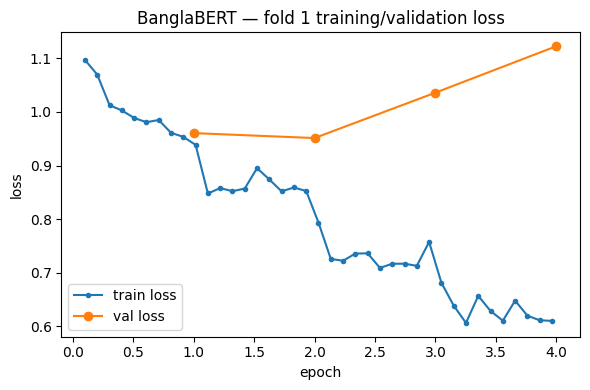

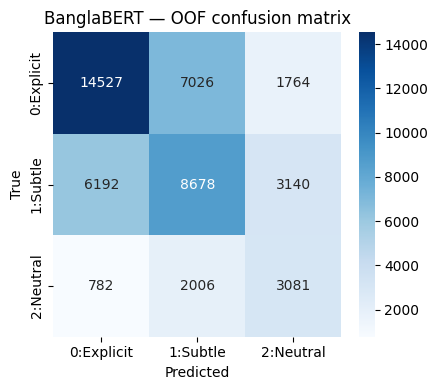

In [17]:
bangla_oof, bangla_test, f1_bangla, bangla_loss_hist = run_kfold_transformer(
    "csebuetnlp/banglabert", tag="banglabert"
)
results["BanglaBERT (K-fold)"] = f1_bangla
print(classification_report(y_all, bangla_oof.argmax(1), digits=3))
plot_loss(bangla_loss_hist, "BanglaBERT — fold 1 training/validation loss")
plot_confmat(y_all, bangla_oof.argmax(1), "BanglaBERT — OOF confusion matrix", cmap="Blues")


## 7. Approach 3 — mBERT (`bert-base-multilingual-cased`), K-fold fine-tuning

Trained jointly on 104 languages — pairs well with BanglaBERT because it tends to do better on
the English-heavy / heavily romanized posts, giving the ensemble complementary strengths.

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/47196 [00:00<?, ? examples/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

Fold 3 Macro F1: 0.5301



mbert OOF Macro F1: 0.5313  (per-fold: [0.5313, 0.5321, 0.5301])
              precision    recall  f1-score   support

           0      0.676     0.623     0.648     23317
           1      0.497     0.507     0.502     18010
           2      0.399     0.499     0.443      5869

    accuracy                          0.563     47196
   macro avg      0.524     0.543     0.531     47196
weighted avg      0.573     0.563     0.567     47196



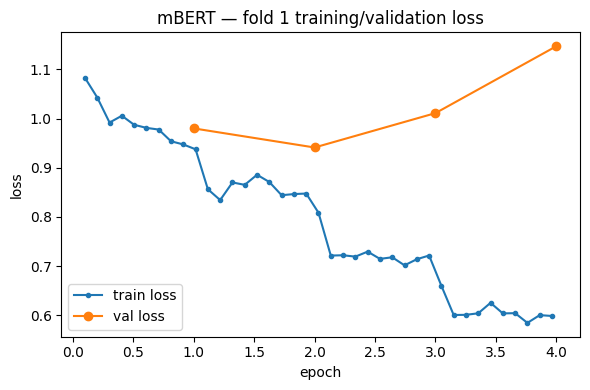

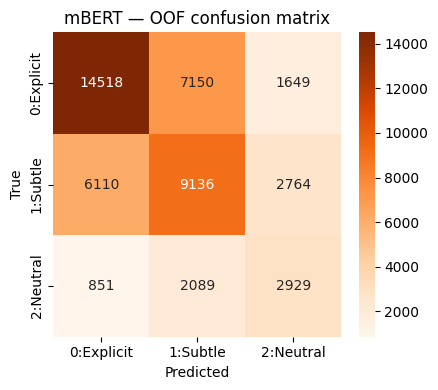

In [18]:
mbert_oof, mbert_test, f1_mbert, mbert_loss_hist = run_kfold_transformer(
    "bert-base-multilingual-cased", tag="mbert"
)
results["mBERT (K-fold)"] = f1_mbert
print(classification_report(y_all, mbert_oof.argmax(1), digits=3))
plot_loss(mbert_loss_hist, "mBERT — fold 1 training/validation loss")
plot_confmat(y_all, mbert_oof.argmax(1), "mBERT — OOF confusion matrix", cmap="Oranges")


## 8. Model comparison & weighted ensemble

All three approaches now have **row-aligned OOF probabilities** over the full (deduped) train
set, so we can grid-search soft-vote weights directly against OOF Macro F1 rather than guessing
weights.

              Model  OOF Macro F1
     mBERT (K-fold)        0.5313
BanglaBERT (K-fold)        0.5263
  LightGBM + MiniLM        0.5180
 LinearSVM + MiniLM        0.5029
    LogReg + MiniLM        0.4912


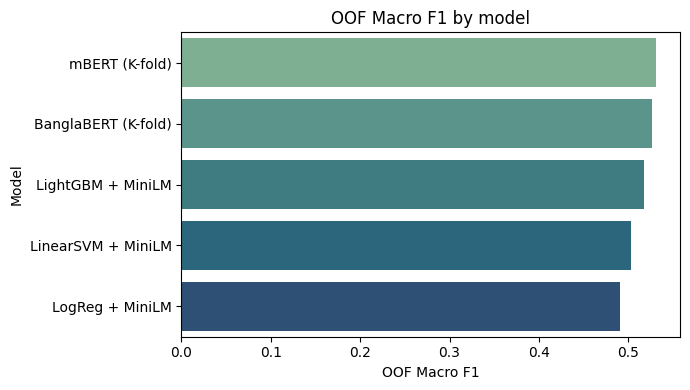

In [19]:
comparison_df = pd.DataFrame(sorted(results.items(), key=lambda kv: -kv[1]), columns=["Model", "OOF Macro F1"])
comparison_df["OOF Macro F1"] = comparison_df["OOF Macro F1"].round(4)
print(comparison_df.to_string(index=False))

plt.figure(figsize=(7, 4))
sns.barplot(data=comparison_df, x="OOF Macro F1", y="Model", palette="crest")
plt.title("OOF Macro F1 by model"); plt.tight_layout(); plt.show()


Best ensemble weights -> embed=0.5, banglaBERT=0.25, mBERT=0.25
Best ensemble OOF Macro F1: 0.5594
  standalone embed: 0.5180
  standalone bangla: 0.5263
  standalone mbert: 0.5313

>>> Best overall strategy: Weighted ensemble  (OOF Macro F1 = 0.5594)


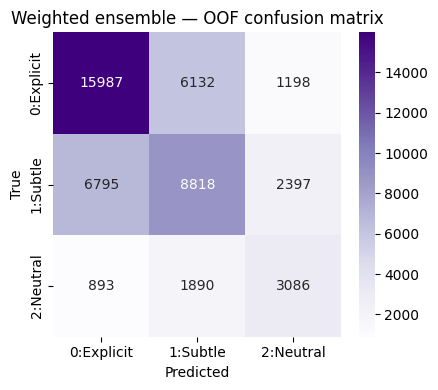

              precision    recall  f1-score   support

           0      0.675     0.686     0.680     23317
           1      0.524     0.490     0.506     18010
           2      0.462     0.526     0.492      5869

    accuracy                          0.591     47196
   macro avg      0.554     0.567     0.559     47196
weighted avg      0.591     0.591     0.590     47196



In [20]:
# Grid-search convex-combination weights over the 3 approaches to maximize OOF Macro F1.
prob_sets = {"embed": best_embed_oof, "bangla": bangla_oof, "mbert": mbert_oof}
test_sets = {"embed": best_embed_test, "bangla": bangla_test, "mbert": mbert_test}
f1_sets = {"embed": best_embed_f1, "bangla": f1_bangla, "mbert": f1_mbert}

best_combo, best_f1 = None, -1
step = 0.05
grid = np.round(np.arange(0, 1.0 + 1e-9, step), 2)
for w_embed in grid:
    for w_bangla in np.round(np.arange(0, 1.0 - w_embed + 1e-9, step), 2):
        w_mbert = round(1.0 - w_embed - w_bangla, 2)
        if w_mbert < 0:
            continue
        blend = w_embed * prob_sets["embed"] + w_bangla * prob_sets["bangla"] + w_mbert * prob_sets["mbert"]
        f1 = f1_score(y_all, blend.argmax(1), average="macro")
        if f1 > best_f1:
            best_f1, best_combo = f1, (w_embed, w_bangla, w_mbert)

print(f"Best ensemble weights -> embed={best_combo[0]}, banglaBERT={best_combo[1]}, mBERT={best_combo[2]}")
print(f"Best ensemble OOF Macro F1: {best_f1:.4f}")

for name, f1 in f1_sets.items():
    print(f"  standalone {name}: {f1:.4f}")

candidates = {**{f"{k} (standalone)": v for k, v in f1_sets.items()}, "Weighted ensemble": best_f1}
BEST_STRATEGY = max(candidates, key=candidates.get)
print(f"\n>>> Best overall strategy: {BEST_STRATEGY}  (OOF Macro F1 = {candidates[BEST_STRATEGY]:.4f})")

ensemble_oof_pred = (best_combo[0]*prob_sets["embed"] + best_combo[1]*prob_sets["bangla"] + best_combo[2]*prob_sets["mbert"]).argmax(1)
plot_confmat(y_all, ensemble_oof_pred, "Weighted ensemble — OOF confusion matrix", cmap="Purples")
print(classification_report(y_all, ensemble_oof_pred, digits=3))


## 9. Final test prediction: ensemble + duplicate-lookup override

In [21]:
w_embed, w_bangla, w_mbert = best_combo
final_test_probs = w_embed * test_sets["embed"] + w_bangla * test_sets["bangla"] + w_mbert * test_sets["mbert"]
final_test_pred = final_test_probs.argmax(axis=1)

# Exact-match lookup override: trust the known train label wherever the cleaned test text
# is an exact duplicate of a (deduped, majority-voted) train text.
overridden = 0
final_pred_list = list(final_test_pred)
for i, ct in enumerate(test_df["clean_text"].values):
    if ct in DUP_LOOKUP:
        lbl = DUP_LOOKUP[ct]
        if lbl != final_pred_list[i]:
            overridden += 1
        final_pred_list[i] = lbl
final_test_pred = np.array(final_pred_list)
print(f"Predictions changed by the duplicate-lookup override: {overridden} / {len(test_df)}")

submission = pd.DataFrame({"id": test_df["id"].values, "y_pred": final_test_pred})
submission.to_csv("/kaggle/working/submission.csv", index=False)
print("\nSaved /kaggle/working/submission.csv")
print(f"Strategy: weighted ensemble (embed={w_embed}, banglaBERT={w_bangla}, mBERT={w_mbert}) + duplicate-lookup override")
submission.head(10)


Predictions changed by the duplicate-lookup override: 35 / 11955

Saved /kaggle/working/submission.csv
Strategy: weighted ensemble (embed=0.5, banglaBERT=0.25, mBERT=0.25) + duplicate-lookup override


,id,y_pred
0,7891,1
1,58497,1
2,8995,2
3,17207,1
4,3148,0
5,57062,0
6,40445,2
7,42252,2
8,35905,0
9,1078,0


## 10. Results summary

In [22]:
final_summary = pd.DataFrame(sorted(candidates.items(), key=lambda kv: -kv[1]), columns=["Model / Strategy", "OOF Macro F1"])
final_summary["OOF Macro F1"] = final_summary["OOF Macro F1"].round(4)
print(final_summary.to_string(index=False))

print("\nPredicted test-set class distribution:")
print(pd.Series(final_test_pred).value_counts(normalize=True).sort_index().round(3))
print("\nTrue train-set class distribution (for comparison):")
print(train_df["label"].value_counts(normalize=True).sort_index().round(3))


   Model / Strategy  OOF Macro F1
  Weighted ensemble        0.5594
 mbert (standalone)        0.5313
bangla (standalone)        0.5263
 embed (standalone)        0.5180

Predicted test-set class distribution:
0    0.511
1    0.355
2    0.135
Name: proportion, dtype: float64

True train-set class distribution (for comparison):
label
0    0.494
1    0.382
2    0.124
Name: proportion, dtype: float64


## Notes for the submission writeup

- **Data:** only the competition-provided `train.csv` / `test.csv`; no external data.
- **Cleaning:** de-duplicated on exact text with majority-vote relabeling (resolves 52 label
  conflicts found in EDA); URL/HTML/mention stripping; emoji → descriptive text tokens;
  repeated character/punctuation normalization; Bangla Unicode and code-mixing preserved as-is.
- **Class imbalance:** inverse-frequency class weights in every model's loss function
  (`class_weight="balanced"` for classical models, weighted `CrossEntropyLoss` for transformers).
- **Validation:** stratified K-fold (5-fold for the embedding baseline, 3-fold for each
  transformer), with true out-of-fold Macro F1 reported for every model — no row is ever scored
  by a model that trained on it.
- **Models:** `paraphrase-multilingual-MiniLM-L12-v2` embeddings → LogReg/SVM/LightGBM;
  `csebuetnlp/banglabert` fine-tuned end-to-end; `bert-base-multilingual-cased` fine-tuned
  end-to-end. Shared transformer hyperparameters: max_len=160, lr=2e-5, AdamW, batch 16/32,
  up to 4 epochs with early stopping (patience 2), weight decay 0.01, 6% linear warmup, fp16.
- **Ensembling:** soft-vote weights grid-searched (step 0.05) directly against OOF Macro F1.
- **Post-processing:** exact-match lookup overrides predictions for the ~2% of test rows whose
  cleaned text is verbatim present in the (deduped) training data — uses only the provided
  dataset, per the competition rules.
- **Seed:** 42 everywhere for reproducibility; minor run-to-run variation from GPU
  non-determinism is expected.
- **Honest caveat:** 52 same-text/different-label conflicts found directly in the training data
  mean there is a real, measurable label-noise ceiling — no model, however good, can perfectly
  separate "explicit" from "subtle" toxicity when human annotators themselves disagreed on
  identical text. Treat any specific target leaderboard score as aspirational, not guaranteed.
- **If you have more compute time before the deadline:** raise `N_FOLDS_TRANSFORMER` to 5,
  add a third multilingual backbone (e.g. `xlm-roberta-base`, which often edges out mBERT) to
  the ensemble, or try `xlm-roberta-large` for one extra fold as a single high-capacity model —
  all straightforward extensions of `run_kfold_transformer` above.
